# Аналитическое решение и разностные схемы

$y'' + a y' = b,\quad y(x_0)=y_0,\quad y'(x_0)=v_0$

Вся логика лежит в `ode_schemes.py`. В ноутбуке только параметры, вызовы и сохранение рисунков для статьи.

In [2]:
# Перечитывать ode_schemes.py после каждой правки, без перезапуска ядра
%load_ext autoreload
%autoreload 2
%config InlineBackend.figure_format = "retina"

from pathlib import Path
import matplotlib.pyplot as plt

from ode_schemes import (
    Problem, solve_all, time_all, max_error, convergence_table,
    plot_solutions, plot_errors, plot_convergence,
)

# Единый стиль для всех рисунков статьи
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 12,
    "legend.fontsize": 9,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Базовый расчёт

In [3]:
problem = Problem(a=2, b=1, y0=1.0, v0=2.0)
h = 0.1

x, y_exact, solutions = solve_all(problem, h)
times = time_all(problem, h)
for name, y in solutions.items():
    print(f"{name}: ошибка {max_error(y, y_exact):.3e}, время {times[name] * 1e3:.4f} мс")

Разностная схема (7): 5.251e-03
Разностная схема (9): 8.882e-16


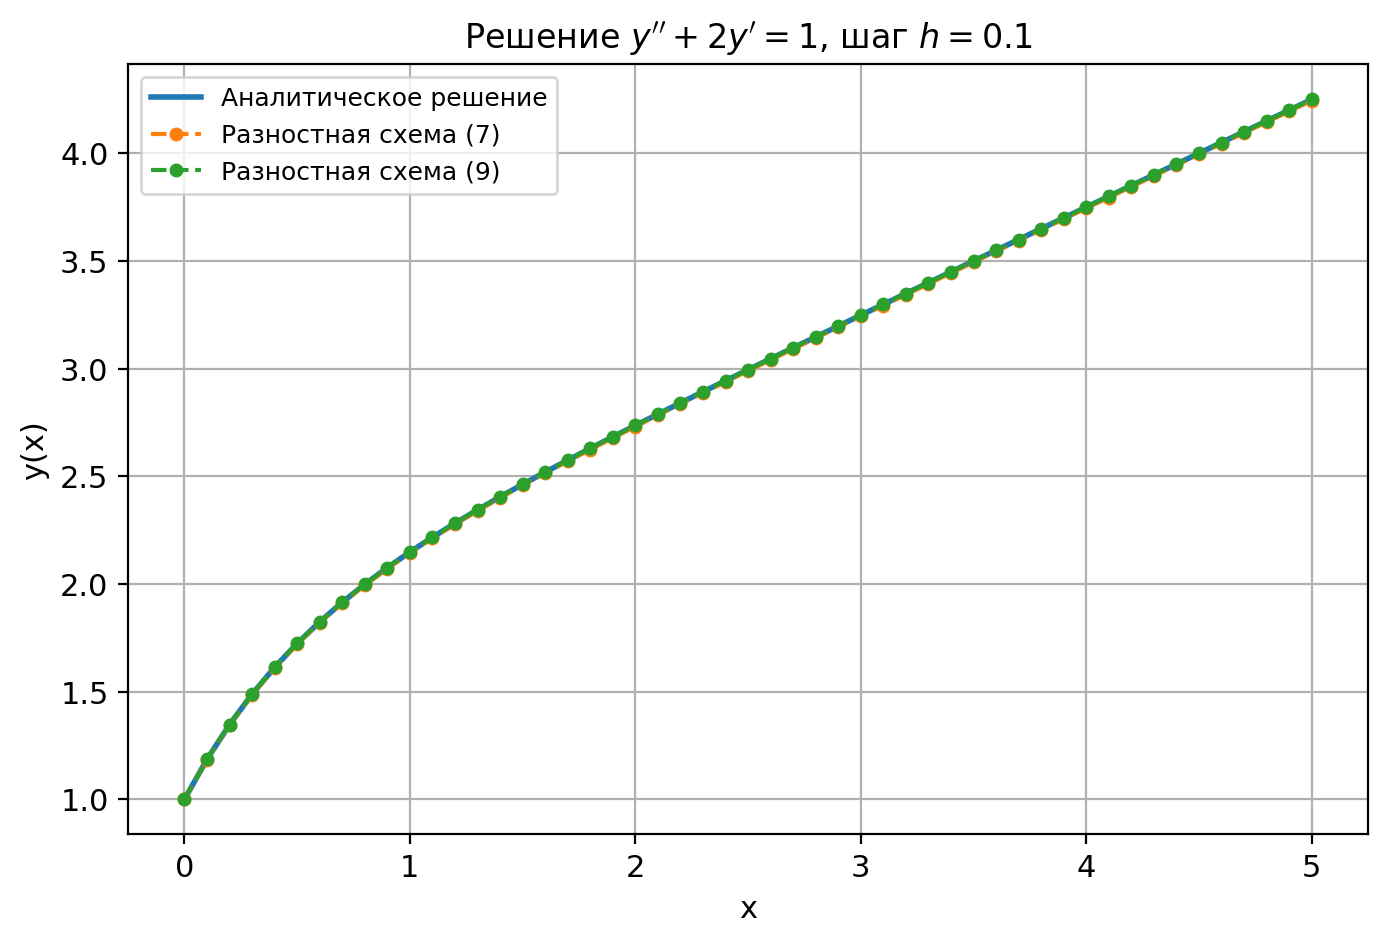

In [4]:
ax = plot_solutions(problem, h, x, y_exact, solutions)
ax.figure.savefig(FIG_DIR / "solutions.pdf")

## Рисунок из двух панелей: решение и погрешность

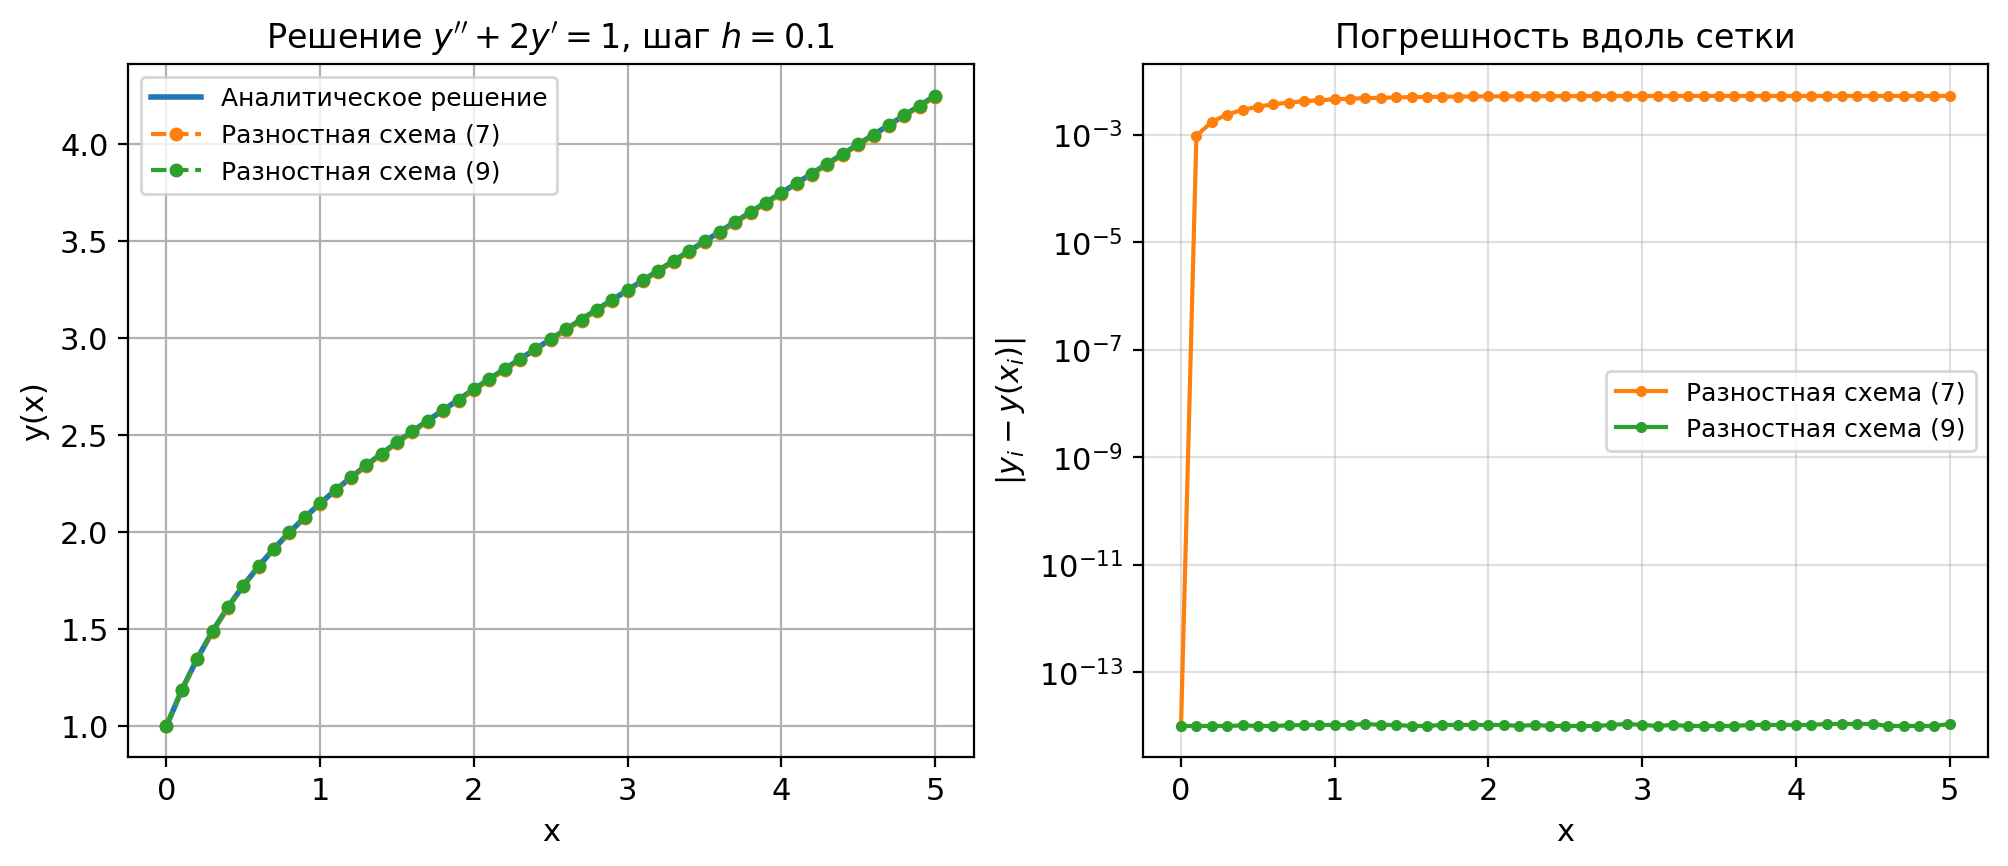

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
plot_solutions(problem, h, x, y_exact, solutions, ax=ax1)
plot_errors(x, y_exact, solutions, ax=ax2)
fig.savefig(FIG_DIR / "solutions_and_errors.pdf")

## Сходимость по шагу

         h      Разностная схема (7)      Разностная схема (9)
       0.2                 2.202e-02                 1.776e-15
       0.1                 5.251e-03                 8.882e-16
      0.05                 1.281e-03                 4.441e-15
     0.025                 3.164e-04                 2.220e-15
    0.0125                 7.861e-05                 2.398e-14


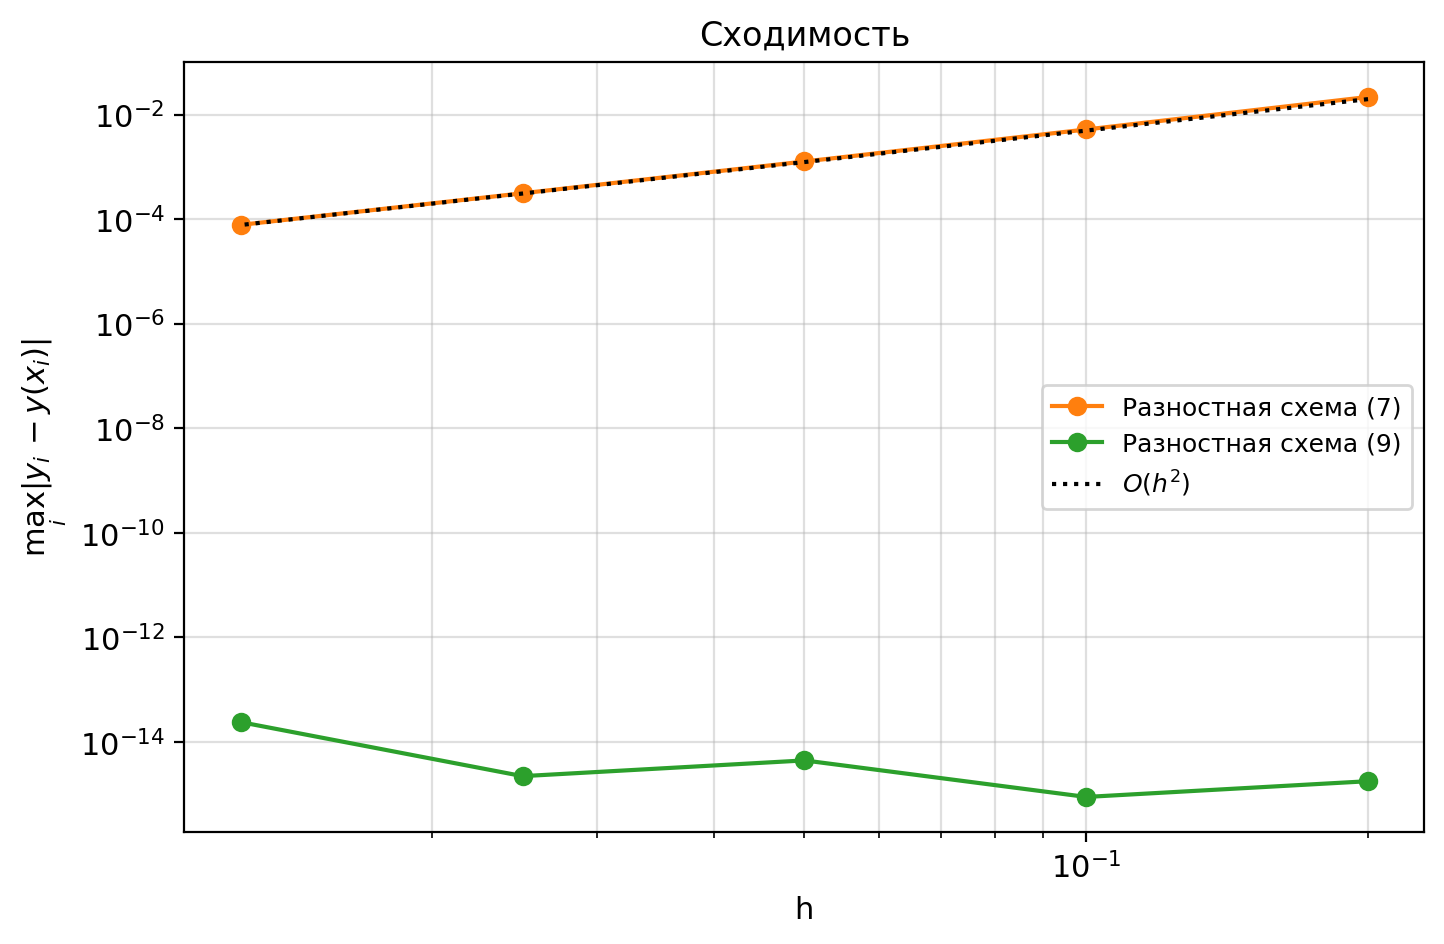

In [6]:
steps = [0.2, 0.1, 0.05, 0.025, 0.0125]
convergence_table(problem, steps)

ax = plot_convergence(problem, steps)
ax.loglog(steps, [0.5 * h**2 for h in steps], "k:", label=r"$O(h^2)$")  # опорная прямая
ax.legend()
ax.figure.savefig(FIG_DIR / "convergence.pdf")

## Серия расчётов при разных $a$

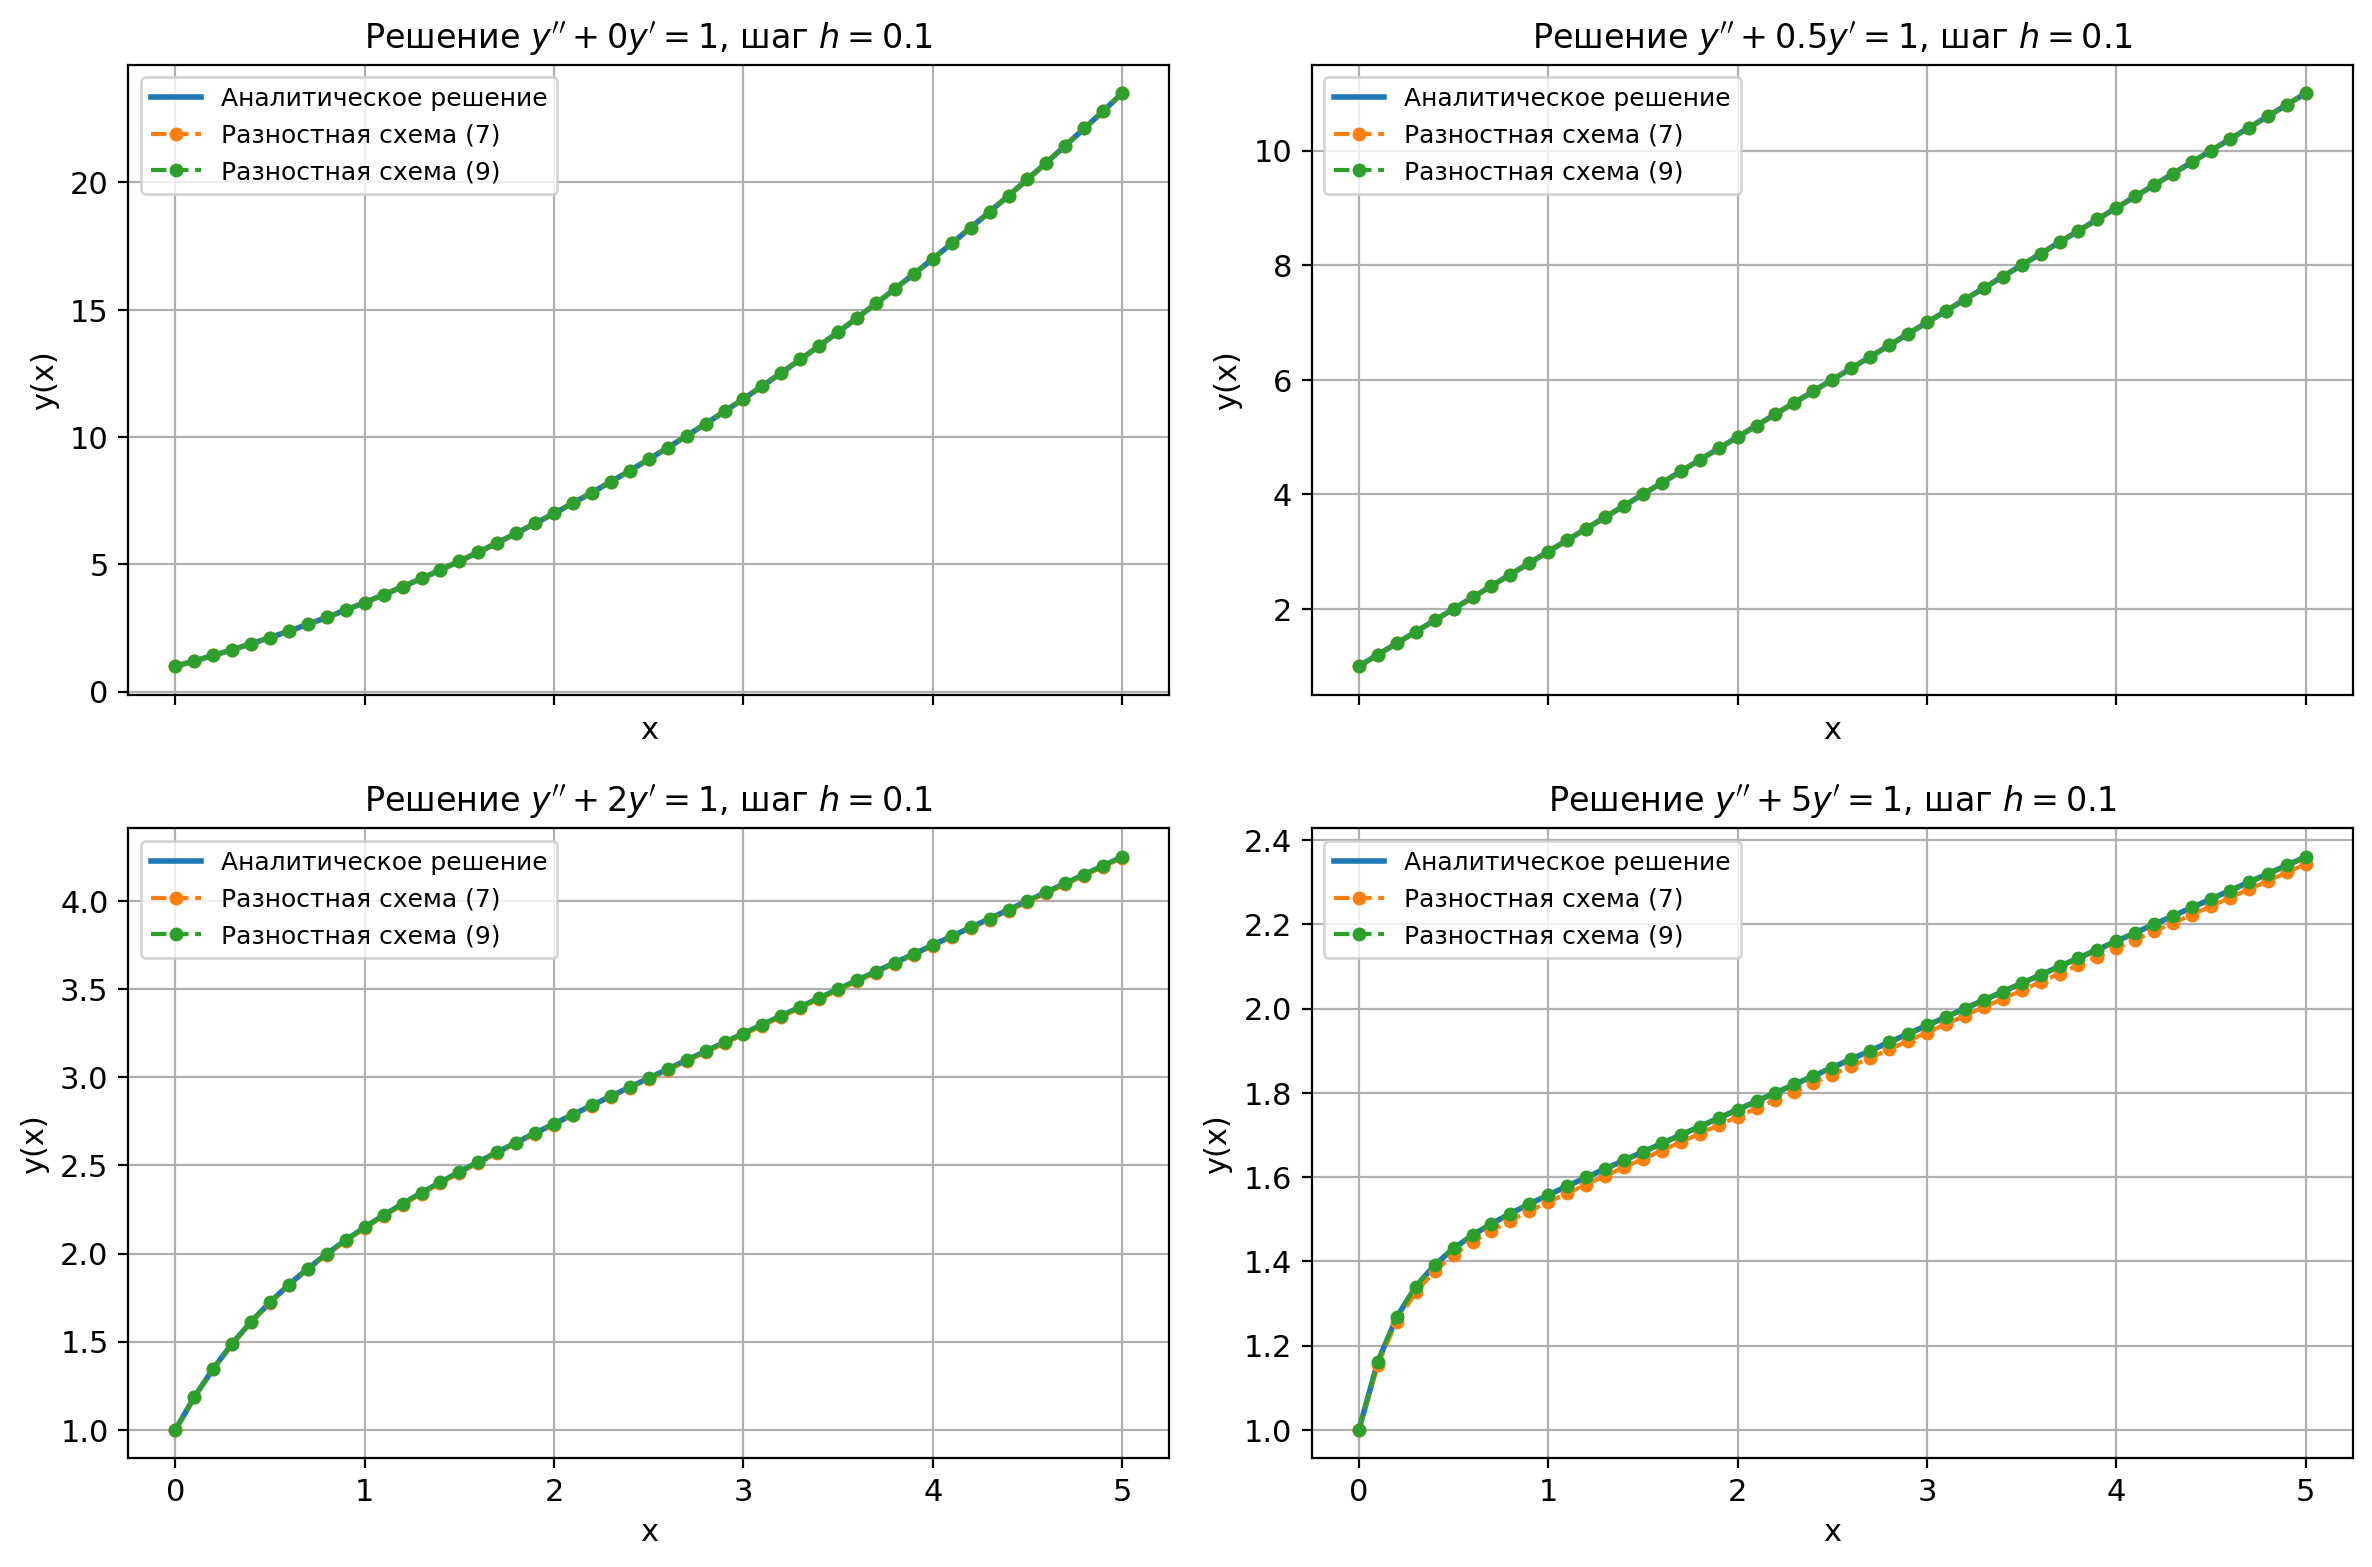

In [7]:
a_values = [0, 0.5, 2, 5]
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)

for a, ax in zip(a_values, axes.flat):
    p = Problem(a=a, b=1, y0=1.0, v0=2.0)
    plot_solutions(p, h, *solve_all(p, h), ax=ax)

fig.tight_layout()
fig.savefig(FIG_DIR / "a_sweep.pdf")